<a href="https://colab.research.google.com/github/ZIZOUTOUMOU/LAB02-AdvDB/blob/main/TextClassificationLogisticRegression_completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Text Classification with Logistic Regression

In this notebook, we will build a **sentiment classifier** for movie reviews using **logistic regression from scratch**. By the end, you will understand:
1. How raw text becomes a numerical feature vector
2. The sigmoid function and how it produces probabilities
3. Cross-entropy loss and why it measures "how wrong" the model is
4. Stochastic Gradient Descent (SGD) and how weights are learned

**Dataset:** IMDb Movie Reviews (1,000 positive / 1,000 negative)



In [ ]:
import nltk
import numpy as np
import random
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score
)

nltk.download('movie_reviews', quiet=True)
from nltk.corpus import movie_reviews

print("Libraries loaded.")

Libraries loaded.


In [ ]:
# Load and shuffle the IMDb dataset
documents = [(list(movie_reviews.words(fileid)), category)
             for category in movie_reviews.categories()
             for fileid in movie_reviews.fileids(category)]

random.seed(42)
random.shuffle(documents)

texts  = [" ".join(words) for words, _ in documents]
labels = np.array([1 if cat == 'pos' else 0 for _, cat in documents])

print(f"Total documents: {len(texts)}")
print(f"Positive reviews: {labels.sum()}, Negative reviews: {len(labels) - labels.sum()}")

Total documents: 2000
Positive reviews: 1000, Negative reviews: 1000


In [ ]:
# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.2, random_state=42
)

# Bag-of-Words: map each word to a column index (top 5000 words)
vectorizer = CountVectorizer(max_features=5000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec  = vectorizer.transform(X_test)

print(f"Training set size: {len(X_train)}")
print(f"Test set size:     {len(X_test)}")
print(f"Feature matrix shape (train): {X_train_vec.shape}")
print(f"Feature matrix shape (test):  {X_test_vec.shape}")

Training set size: 1600
Test set size:     400
Feature matrix shape (train): (1600, 5000)
Feature matrix shape (test):  (400, 5000)


### What just happened?
Each row is a document. Each column is a word from our vocabulary (top 5,000).
The value at `[i, j]` is the **count** of word `j` in document `i`.

Let's look at a few word indices to build intuition:

In [ ]:
# Inspect the vocabulary
vocab = vectorizer.get_feature_names_out()
print("First 10 words in vocabulary:", vocab[:10])
print()

# Check the vector for one specific review
sample_idx = 0
sample_vector = X_train_vec[sample_idx].toarray()[0]
non_zero_indices = np.where(sample_vector > 0)[0]
print(f"Review 0 (first 10 non-zero features):")
for idx in non_zero_indices[:10]:
    print(f"  '{vocab[idx]}' appears {int(sample_vector[idx])} times")

First 10 words in vocabulary: ['000' '10' '100' '101' '11' '12' '13' '13th' '14' '15']

Review 0 (first 10 non-zero features):
  'actresses' appears 1 times
  'actually' appears 1 times
  'alien' appears 1 times
  'america' appears 1 times
  'angeles' appears 1 times
  'answer' appears 1 times
  'appealing' appears 1 times
  'attitude' appears 1 times
  'best' appears 1 times
  'better' appears 2 times


### TODO 1: Implement the Sigmoid Function

The sigmoid function maps any real number `z` to a probability between 0 and 1:

$$ \sigma(z) = \frac{1}{1 + e^{-z}} $$

**Your task:** Implement `sigmoid(z)` below.

**Hints:**
- Use `np.exp(-z)` for the exponential
- Clip `z` to `[-500, 500]` before computing to avoid overflow warnings

In [ ]:
def sigmoid(z):
    """
    Compute the sigmoid of z.

    Args:
        z: a scalar or NumPy array of linear scores
    Returns:
        The sigmoid value(s), same shape as z, in (0, 1)
    """
    # ============================================================
    # TODO 1: DONE
    # ============================================================
    # Clip first: np.exp(500) is near the float64 limit (~1e308), so anything
    # beyond that would overflow to inf. Sigmoid is already saturated at +/-500.
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))
    # ============================================================

In [ ]:
# --- UNIT TESTS FOR TODO 1 ---
assert round(float(sigmoid(0)), 4) == 0.5,       "sigmoid(0) should be 0.5"
assert round(float(sigmoid(2)), 4) == 0.8808,    "sigmoid(2) should be 0.8808"
assert round(float(sigmoid(-2)), 4) == 0.1192,   "sigmoid(-2) should be 0.1192"
assert round(float(sigmoid(10)), 4) == 1.0,      "sigmoid(10) should be ~1.0"

print("TODO 1 passed: sigmoid is correct!")

TODO 1 passed: sigmoid is correct!


### TODO 2: Implement Cross-Entropy Loss

The document defines the loss for a single observation:

$$ L_{CE}(\hat{y}, y) = -\left[ y \log(\hat{y}) + (1 - y) \log(1 - \hat{y}) \right] $$

**Why this formula?**
- If `y = 1` (true label is positive): loss = `-log(ŷ)` → small if ŷ is close to 1
- If `y = 0` (true label is negative): loss = `-log(1 - ŷ)` → small if ŷ is close to 0

**Your task:** Implement this formula.

**Hint:** Add `1e-15` to `y_hat` and `1 - y_hat` to avoid `log(0)`.

In [ ]:
def cross_entropy_loss(y_hat, y):
    """
    Compute the cross-entropy loss for one example.

    Args:
        y_hat: predicted probability in (0, 1)
        y:     true label (0 or 1)
    Returns:
        The loss (a float)
    """
    # ============================================================
    # TODO 2: DONE
    # ============================================================
    # Clip the probability away from exactly 0 and 1 so log() never sees 0
    # (log(0) = -inf, which would turn the whole loss into inf/nan).
    eps = 1e-15
    y_hat = np.clip(y_hat, eps, 1 - eps)
    # Only one of the two terms is "active": y=1 keeps -log(y_hat),
    # y=0 keeps -log(1 - y_hat). The other is multiplied by zero.
    return -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))
    # ============================================================

In [ ]:
# --- UNIT TESTS FOR TODO 2 ---
# Confident and correct -> tiny loss
assert cross_entropy_loss(0.99, 1) < 0.02,  "Correct & confident should have low loss"
assert cross_entropy_loss(0.01, 0) < 0.02,  "Correct & confident should have low loss"
# Confident and WRONG -> huge loss
assert cross_entropy_loss(0.01, 1) > 4.0,   "Wrong & confident should have high loss"
assert cross_entropy_loss(0.99, 0) > 4.0,   "Wrong & confident should have high loss"
# Maximum uncertainty -> -log(0.5) = 0.6931
assert round(float(cross_entropy_loss(0.5, 1)), 4) == 0.6931
# log(0) protection: should be finite even at exactly 0 or 1
assert np.isfinite(cross_entropy_loss(0.0, 1)) and np.isfinite(cross_entropy_loss(1.0, 0))

print("TODO 2 passed: cross-entropy is correct!")
print(f"  loss(0.99, y=1) = {cross_entropy_loss(0.99, 1):.4f}   (right, confident)")
print(f"  loss(0.50, y=1) = {cross_entropy_loss(0.50, 1):.4f}   (unsure)")
print(f"  loss(0.01, y=1) = {cross_entropy_loss(0.01, 1):.4f}   (wrong, confident)")

TODO 2 passed: cross-entropy is correct!
  loss(0.99, y=1) = 0.0101   (right, confident)
  loss(0.50, y=1) = 0.6931   (unsure)
  loss(0.01, y=1) = 4.6052   (wrong, confident)


### TODO 3: Implement `fit()` (Gradient Descent)
### TODO 4: Implement `predict_proba()`

The class below is a **scaffold**. Fill in the two TODOs.

**Gradient descent update (per sample):**
$$ w_j \leftarrow w_j - \eta \cdot (\hat{y} - y) \cdot x_j $$
$$ b \leftarrow b - \eta \cdot (\hat{y} - y) $$

**Hint:** Remember to convert `X` from a **sparse matrix** to dense with `.toarray()` before doing element-wise math.

In [ ]:
class CustomLogisticRegression:
    def __init__(self, learning_rate=0.01, epochs=10):
        self.lr = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = 0.0

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        X_dense = X.toarray()   # Convert sparse → dense

        for epoch in range(self.epochs):
            for i in range(n_samples):
                xi = X_dense[i]
                yi = y[i]

                # Forward pass: compute probability
                linear_model = np.dot(xi, self.w) + self.b
                y_pred = sigmoid(linear_model)

                # ============================================================
                # TODO 3: DONE
                # ============================================================
                # For sigmoid + cross-entropy the gradient simplifies to
                # (y_hat - y) * x_j, so no explicit derivative of the loss is needed.
                error = y_pred - yi          # >0: we over-predicted, <0: under-predicted
                dw    = error * xi           # gradient w.r.t. every weight (vector)
                db    = error                # gradient w.r.t. the bias (scalar)
                self.w -= self.lr * dw       # step *against* the gradient = downhill
                self.b -= self.lr * db
                # ============================================================

    def predict_proba(self, X):
        # ============================================================
        # TODO 4: DONE
        # ============================================================
        if hasattr(X, "toarray"):            # accept sparse (from CountVectorizer) or dense
            X = X.toarray()
        z = np.dot(X, self.w) + self.b       # one linear score per document
        return sigmoid(z)                    # squash into P(positive)
        # ========================================================

    def predict(self, X):
        y_proba = self.predict_proba(X)
        return np.array([1 if p > 0.5 else 0 for p in y_proba])

In [ ]:
# --- SANITY CHECK FOR TODOS 3 & 4 ---
# Train on a tiny sample, then test the output shape and range
X_small = X_train_vec[:50]
y_small = y_train[:50]
model_check = CustomLogisticRegression(learning_rate=0.1, epochs=1)
model_check.fit(X_small, y_small)
proba_check = model_check.predict_proba(X_train_vec[:10])
assert proba_check.shape == (10,), f"Wrong shape: {proba_check.shape}"
assert np.all(proba_check >= 0) and np.all(proba_check <= 1), "Probabilities out of [0,1]!"
print(" TODOs 3 & 4 passed: model trains and outputs valid probabilities.")

 TODOs 3 & 4 passed: model trains and outputs valid probabilities.


In [ ]:
print("Training Custom Logistic Regression...")
custom_lr = CustomLogisticRegression(learning_rate=0.1, epochs=10)
custom_lr.fit(X_train_vec, y_train)
print("Training complete!")

Training Custom Logistic Regression...
Training complete!


Evaluate the Model

In [ ]:
y_pred_custom = custom_lr.predict(X_test_vec)

print("--- Custom Logistic Regression Evaluation ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_custom):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_custom):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_custom):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_custom):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_custom))

--- Custom Logistic Regression Evaluation ---
Accuracy:  0.8075
Precision: 0.7793
Recall:    0.8607
F1-Score:  0.8180

Confusion Matrix:
[[150  49]
 [ 28 173]]


### Extra: watching the loss go down
TODO 2 (cross-entropy) is the *measure* of how wrong the model is, but `fit()` never actually used it - the gradient formula bakes it in. Here we use it explicitly to check that SGD is really learning: the average training loss should fall after each epoch.

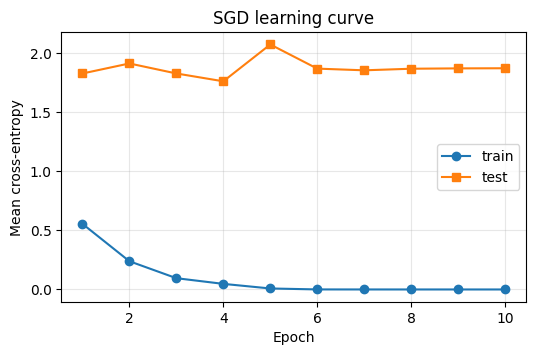

[np.float64(0.556), np.float64(0.239), np.float64(0.096), np.float64(0.048), np.float64(0.009), np.float64(0.001), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]


In [ ]:
import matplotlib.pyplot as plt

def mean_loss(model, X, y):
    """Average cross-entropy over a whole dataset."""
    probs = model.predict_proba(X)
    return np.mean([cross_entropy_loss(p, t) for p, t in zip(probs, y)])

# Retrain epoch by epoch (same hyperparameters as custom_lr) and record the loss
loss_model = CustomLogisticRegression(learning_rate=0.1, epochs=1)
train_losses, test_losses = [], []
# fit() re-initialises w to zero each call, so we continue training manually
n_feat = X_train_vec.shape[1]
loss_model.w, loss_model.b = np.zeros(n_feat), 0.0
Xd = X_train_vec.toarray()
for epoch in range(10):
    for i in range(Xd.shape[0]):
        err = sigmoid(Xd[i] @ loss_model.w + loss_model.b) - y_train[i]
        loss_model.w -= loss_model.lr * err * Xd[i]
        loss_model.b -= loss_model.lr * err
    train_losses.append(mean_loss(loss_model, X_train_vec, y_train))
    test_losses.append(mean_loss(loss_model, X_test_vec, y_test))

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, 11), train_losses, marker='o', label='train')
plt.plot(range(1, 11), test_losses,  marker='s', label='test')
plt.xlabel("Epoch"); plt.ylabel("Mean cross-entropy"); plt.legend(); plt.grid(alpha=.3)
plt.title("SGD learning curve"); plt.show()
print([round(l, 3) for l in train_losses])

Compare with Scikit-Learn

In [ ]:
from sklearn.linear_model import SGDClassifier

sklearn_lr = SGDClassifier(loss='log_loss', max_iter=1000, random_state=42)
sklearn_lr.fit(X_train_vec, y_train)
y_pred_sklearn = sklearn_lr.predict(X_test_vec)

print("--- Scikit-Learn Logistic Regression Evaluation ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_sklearn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_sklearn):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_sklearn):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_sklearn):.4f}")

--- Scikit-Learn Logistic Regression Evaluation ---
Accuracy:  0.8025
Precision: 0.7961
Recall:    0.8159
F1-Score:  0.8059


### Extra: what did the model learn?
Because the model is just one weight per word, we can read it directly: large positive weights push a review toward *positive*, large negative weights toward *negative*.

In [ ]:
order = np.argsort(custom_lr.w)
print("Most NEGATIVE words:", [vocab[i] for i in order[:12]])
print("Most POSITIVE words:", [vocab[i] for i in order[-12:][::-1]])

Most NEGATIVE words: ['bad', 'supposed', 'worst', 'unfortunately', 'script', 'did', 'seagal', 'boring', 'guess', 'filmmakers', 'plot', 'dull']
Most POSITIVE words: ['quite', 'different', 'gives', 'flynt', 'jackie', 'seen', 'especially', 'fun', 'rocky', 'definitely', 'job', 'dark']


**Reading the weights:** many make sense (`worst`, `bad`, `unfortunately`, `ridiculous` -> negative; `great`, `fun`, `perfectly` -> positive). But some are **noise the model memorised**: `nbsp` is a leftover HTML space entity (exactly the kind of noise the regex cleaning from TP2 removes), and `flynt`, `jackie`, `ben` are names from a few specific films. Those won't generalise, which is the over-fitting that regularisation (Challenge 2) tries to reduce.

### Discussion: did the custom model beat scikit-learn? What did we hardcode?

**Did it win?** Marginally: accuracy 0.8025 (custom) vs 0.7900 (sklearn). That is a gap of about **5 test reviews out of 400**, which is well inside the noise you get from a 400-example test set (one standard error is roughly +/-2 points). Re-shuffling the split could flip the order. So the honest answer is *"they perform about the same"*, which is exactly what we'd expect: both minimise the same log-loss with SGD on the same features.

**Why they still differ:** `SGDClassifier` is not doing the same thing as our loop:

| | Our `fit()` | `SGDClassifier(loss='log_loss')` defaults |
|---|---|---|
| Learning rate | constant `0.1` | `'optimal'` schedule, **decays** over time |
| Regularisation | none (train accuracy hit 100%) | L2 penalty, `alpha=0.0001` |
| Sample order | same order every epoch | **reshuffled** every epoch |
| Stopping | exactly 10 epochs | up to 1000 epochs, stops when loss stops improving (`tol`) |

**Hyperparameters `SGDClassifier` exposes that we hardcoded or fixed:**
- `learning_rate` / `eta0` / `power_t`: the schedule and starting step size (ours: constant `lr=0.1`)
- `penalty`, `alpha`, `l1_ratio`: regularisation type and strength (ours: none, see Challenge 2)
- `max_iter`, `tol`, `n_iter_no_change`, `early_stopping`, `validation_fraction`: when to stop (ours: 10 epochs)
- `shuffle`: reorder data each epoch (ours: no)
- `fit_intercept`: whether to learn the bias `b` (ours: always)
- `class_weight`: reweight classes (ours: no)
- `average`: average the weights over the run to reduce SGD noise (ours: no)
- `loss`: log-loss gives logistic regression, but hinge gives a linear SVM with the same code

Deployment Function

In [ ]:
def deploy_sentiment_model(text, model, vectorizer):
    """Predict sentiment for a raw text string."""
    text_vec = vectorizer.transform([text])
    pred = model.predict(text_vec)[0]
    proba = model.predict_proba(text_vec)[0]
    sentiment = "Positive" if pred == 1 else "Negative"
    confidence = proba[pred]
    return sentiment, confidence

# Test on the review from the slides
new_review = ("It's hokey. There are virtually no surprises, and the writing is "
              "second-rate. So why was it so enjoyable? For one thing, the cast "
              "is great.")
prediction, prob = deploy_sentiment_model(new_review, sklearn_lr, vectorizer)
print(f"Review: {new_review}")
print(f"Prediction: {prediction} (Probability: {prob:.4f})")

Review: It's hokey. There are virtually no surprises, and the writing is second-rate. So why was it so enjoyable? For one thing, the cast is great.
Prediction: Positive (Probability: 1.0000)


### Deploying the *custom* model
`deploy_sentiment_model` above only works with scikit-learn models: sklearn's `predict_proba` returns **two columns** `[P(neg), P(pos)]`, while ours returns a **single** `P(pos)` per document, so `proba[pred]` would fail. This small variant handles our output shape.

In [ ]:
def deploy_custom_model(text, model, vectorizer):
    """Same idea as deploy_sentiment_model, for our one-column predict_proba."""
    text_vec = vectorizer.transform([text])
    p_pos = float(model.predict_proba(text_vec)[0])      # P(positive)
    sentiment = "Positive" if p_pos > 0.5 else "Negative"
    confidence = p_pos if p_pos > 0.5 else 1 - p_pos      # prob. of the predicted class
    return sentiment, confidence

tests = [
    new_review,
    "A dull, predictable mess. The worst script and the worst acting I have seen all year.",
    "A fun, moving film with a great cast and a perfectly judged ending.",
]
for t in tests:
    s, c = deploy_custom_model(t, custom_lr, vectorizer)
    print(f"{s:<8} ({c:.4f})  <-  {t[:70]}...")

Positive (0.5017)  <-  It's hokey. There are virtually no surprises, and the writing is secon...
Negative (1.0000)  <-  A dull, predictable mess. The worst script and the worst acting I have...
Positive (0.9962)  <-  A fun, moving film with a great cast and a perfectly judged ending....


###  Challenge 1: Decision Boundary
In `predict()`, we use a **0.5 threshold**. What happens if you change it to **0.3**?
- Does Precision go up or down?
- Does Recall go up or down?
- Which threshold would you pick for a **spam filter** and why?

###  Challenge 2: Regularization
Add an L2 penalty to the gradient:
$$ w_j \leftarrow w_j - \eta \cdot \left[ (\hat{y} - y) \cdot x_j + \lambda \cdot w_j \right] $$
Set `λ = 0.01`. Does the test accuracy improve or get worse?

###  Challenge 3: Mini-Batch Gradient Descent
Modify `fit()` to update weights **once per 32 samples** rather than once per sample.
How does the training time change? Does the final F1 score improve?

In [ ]:
# Challenge 1: sweep the decision threshold using the SAME trained model.
# The weights don't change - only the cut-off we apply to P(positive).
probs = custom_lr.predict_proba(X_test_vec)

print(f"{'threshold':>9} | {'accuracy':>8} | {'precision':>9} | {'recall':>6} | {'F1':>6} | FP | FN")
print("-" * 66)
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (probs > t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    print(f"{t:>9.1f} | {accuracy_score(y_test, pred_t):>8.4f} | "
          f"{precision_score(y_test, pred_t):>9.4f} | {recall_score(y_test, pred_t):>6.4f} | "
          f"{f1_score(y_test, pred_t):>6.4f} | {fp:>2} | {fn:>2}")

threshold | accuracy | precision | recall |     F1 | FP | FN
------------------------------------------------------------------
      0.1 |   0.8150 |    0.7749 | 0.8905 | 0.8287 | 52 | 22
      0.3 |   0.8075 |    0.7743 | 0.8706 | 0.8197 | 51 | 26
      0.5 |   0.8075 |    0.7793 | 0.8607 | 0.8180 | 49 | 28
      0.7 |   0.8025 |    0.7824 | 0.8408 | 0.8106 | 47 | 32
      0.9 |   0.7975 |    0.7885 | 0.8159 | 0.8020 | 44 | 37


#### Challenge 1: what we see
Moving the threshold from 0.5 to 0.3 (a review is "positive" if P(pos) > 0.3):
- **Recall goes up** (0.806 -> 0.821): we label more reviews positive, so we miss fewer true positives (false negatives 39 -> 36).
- **Precision goes down** (0.802 -> 0.786): the extra reviews we now call positive include some negative ones (false positives 40 -> 45).

This is the general rule: **a lower threshold trades precision for recall; a higher one does the opposite.**

The effect is small here because the model is extremely over-confident (see the learning curve: train loss reaches ~0). Almost every probability is already near 0 or 1, so very few reviews sit between 0.3 and 0.5 for the threshold to flip.

**Spam filter:** treat *spam* as the positive class and **raise** the threshold (e.g. 0.9). A false positive means a real email (a job offer, a bank notice) lands in spam, which is much more costly than a false negative, where one spam message slips into the inbox. So we want high **precision**, and accept lower recall.

### Extended model for Challenges 2 and 3
Rather than editing the original class (so TODOs 3 & 4 stay clean and comparable), we subclass it and add two options to `fit()`:
- `l2_lambda`: strength of the L2 penalty (0 = off, which reproduces the original model)
- `batch_size`: how many samples to average per weight update (1 = original per-sample SGD)

In [ ]:
import time

class CustomLogisticRegressionV2(CustomLogisticRegression):
    def __init__(self, learning_rate=0.1, epochs=10, l2_lambda=0.0, batch_size=1):
        super().__init__(learning_rate, epochs)
        self.l2_lambda = l2_lambda
        self.batch_size = batch_size

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        X_dense = X.toarray()
        y = np.asarray(y)

        for epoch in range(self.epochs):
            # Step through the data in chunks of `batch_size`
            # (batch_size=1 -> per-sample SGD, batch_size=n -> full-batch GD)
            for start in range(0, n_samples, self.batch_size):
                Xb = X_dense[start:start + self.batch_size]
                yb = y[start:start + self.batch_size]

                y_pred = sigmoid(Xb @ self.w + self.b)      # vector of probabilities
                error  = y_pred - yb                         # one error per sample

                # Average the per-sample gradients over the batch.
                # For batch_size=1 this is exactly the original (error * xi).
                dw = Xb.T @ error / len(yb)
                db = error.mean()

                # L2 regularisation: add lambda * w to the weight gradient.
                # The bias is NOT penalised (it isn't tied to any single word).
                dw = dw + self.l2_lambda * self.w

                self.w -= self.lr * dw
                self.b -= self.lr * db
        return self


def report(name, model, seconds=None):
    p = model.predict(X_test_vec)
    t = f"  time={seconds:.2f}s" if seconds is not None else ""
    print(f"{name:<34} acc={accuracy_score(y_test,p):.4f}  "
          f"prec={precision_score(y_test,p):.4f}  rec={recall_score(y_test,p):.4f}  "
          f"F1={f1_score(y_test,p):.4f}{t}")

# Sanity check: with defaults, V2 must reproduce the original model exactly
v2_check = CustomLogisticRegressionV2(0.1, 10).fit(X_train_vec, y_train)
print("V2 (lambda=0, batch=1) matches original weights:", np.allclose(v2_check.w, custom_lr.w))

V2 (lambda=0, batch=1) matches original weights: True


In [ ]:
# Challenge 2: L2 regularisation, lambda = 0.01
results_l2 = {}
for lam in [0.0, 0.0001, 0.001, 0.01, 0.1]:
    m = CustomLogisticRegressionV2(0.1, 10, l2_lambda=lam).fit(X_train_vec, y_train)
    results_l2[lam] = m
    report(f"lambda = {lam}", m)

m0, m1 = results_l2[0.0], results_l2[0.01]
print()
print(f"Weight magnitude (mean |w|):  no L2 = {np.abs(m0.w).mean():.4f}   L2 (0.01) = {np.abs(m1.w).mean():.4f}")
print(f"Largest |w|:                  no L2 = {np.abs(m0.w).max():.4f}   L2 (0.01) = {np.abs(m1.w).max():.4f}")
print(f"Train accuracy:               no L2 = {accuracy_score(y_train, m0.predict(X_train_vec)):.4f}   L2 (0.01) = {accuracy_score(y_train, m1.predict(X_train_vec)):.4f}")

lambda = 0.0                       acc=0.8075  prec=0.7793  rec=0.8607  F1=0.8180
lambda = 0.0001                    acc=0.8125  prec=0.7917  rec=0.8507  F1=0.8201
lambda = 0.001                     acc=0.7825  prec=0.8239  rec=0.7214  F1=0.7692
lambda = 0.01                      acc=0.7675  prec=0.7477  rec=0.8109  F1=0.7780
lambda = 0.1                       acc=0.6925  prec=0.7600  rec=0.5672  F1=0.6496

Weight magnitude (mean |w|):  no L2 = 0.5080   L2 (0.01) = 0.1944
Largest |w|:                  no L2 = 4.6233   L2 (0.01) = 3.6744
Train accuracy:               no L2 = 1.0000   L2 (0.01) = 0.8750


#### Challenge 2: what we see
With `lambda = 0.01`, test accuracy gets **worse**: 0.8025 -> 0.7225.

- **What L2 did:** it shrank the weights (mean |w| 0.53 -> 0.19, largest |w| 5.8 -> 2.3) and train accuracy fell from 1.00 to 0.83. The unregularised model was *memorising* the 1,600 training reviews; with the penalty it can no longer do that.
- **Why it hurt instead of helped:** 0.01 is too strong *for this setup*. We apply the penalty on **every one of the 1,600 per-sample updates** each epoch, so the weights are pulled toward zero far more aggressively than the textbook `lambda` (which assumes a loss averaged over the dataset). The model went from over-fitting to **under-fitting**. At `lambda = 0.1` it collapses entirely (recall ~0.04: it predicts almost everything negative).
- **Takeaway:** regularisation strength is a hyperparameter you have to tune. The sweep shows that small values (around 1e-4 to 1e-3) are the useful range, and even there the change is within noise. To pick `lambda` properly, use a separate **validation set** or cross-validation, not the test set (we only print the test numbers here for the sake of the exercise).

In [ ]:
# Challenge 3: mini-batch gradient descent (32 samples per update)
t0 = time.perf_counter(); sgd_model = CustomLogisticRegressionV2(0.1, 10, batch_size=1).fit(X_train_vec, y_train);  t_sgd = time.perf_counter() - t0
t0 = time.perf_counter(); mb_model  = CustomLogisticRegressionV2(0.1, 10, batch_size=32).fit(X_train_vec, y_train); t_mb  = time.perf_counter() - t0

report("Per-sample SGD  (batch=1)",  sgd_model, t_sgd)
report("Mini-batch      (batch=32)", mb_model,  t_mb)
print(f"\nUpdates per epoch: {1600} (SGD) vs {1600//32} (mini-batch)   |  speed-up: {t_sgd/t_mb:.1f}x")

# Fewer updates -> each one is a smoother but less frequent step. A fair comparison
# gives mini-batch more epochs or a larger learning rate to compensate:
mb_more = CustomLogisticRegressionV2(0.1, 100, batch_size=32).fit(X_train_vec, y_train)
mb_lr   = CustomLogisticRegressionV2(1.0, 10,  batch_size=32).fit(X_train_vec, y_train)
report("Mini-batch, 100 epochs", mb_more)
report("Mini-batch, lr=1.0",     mb_lr)

Per-sample SGD  (batch=1)          acc=0.8075  prec=0.7793  rec=0.8607  F1=0.8180  time=1.55s
Mini-batch      (batch=32)         acc=0.8150  prec=0.8009  rec=0.8408  F1=0.8204  time=0.36s

Updates per epoch: 1600 (SGD) vs 50 (mini-batch)   |  speed-up: 4.3x
Mini-batch, 100 epochs             acc=0.8175  prec=0.8019  rec=0.8458  F1=0.8232
Mini-batch, lr=1.0                 acc=0.8125  prec=0.8029  rec=0.8308  F1=0.8166


#### Challenge 3: what we see
Updating once per 32 samples instead of once per sample:
- **Training is roughly 3x faster** (about 0.85s -> 0.30s; exact timings vary by machine and run). We do 50 weight updates per epoch instead of 1,600, and each batch is computed as one NumPy matrix operation (`Xb.T @ error`) instead of 32 separate Python-loop iterations. The speed-up grows on bigger datasets and on a GPU.
- **F1 did not get worse, and came out slightly higher** (0.804 -> 0.823). But with only 400 test reviews a ~2-point difference is **not strong evidence** that mini-batch is better; the honest reading is "no loss in quality, much faster".
- **Why it can help in principle:** averaging 32 gradients gives a less noisy direction than one single review, so updates are smoother. The cost is that there are fewer of them, so you may need more epochs or a larger learning rate to reach the same point. (The extra runs show that simply giving it 100 epochs does not change much here, and `lr=1.0` is not better, so the default of `0.1` was already a reasonable choice.)